# ITCS 6169/8169 — Computer Vision
## Simple Framework for Contrastive Learning of Visual Representations (SimCLR) Experimental Template

A self-supervised learning template following the structure of the Vision Transformer experimental notebook: imports, project paths, reproducibility, contrastive data augmentations, seeded train/validation split, visualization, network architecture (encoder + projection head), InfoNCE / NT-Xent loss implementation, linear evaluation protocol, and experiment logging.

**Assignment warning:** Self-supervised pretraining methods like SimCLR are designed for feature extraction and downstream fine-tuning/evaluation. Verify with your instructor whether unsupervised contrastive pretraining is permitted for your primary assignment submission.

In [1]:
# Core imports
from pathlib import Path
import random, time, copy, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms, models
from IPython.display import display

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.0+cu130
CUDA available: True


In [2]:
# Optional Google Drive mount for Colab
try:
    from google.colab import drive
    drive.mount('/content/gdrive')
except ImportError:
    print("Not running in Google Colab.")

Not running in Google Colab.


## 1. Set your working directory

Expected dataset structure:

```text
data/
  train/
    class_1/
    class_2/
  test/
    class_1/
    class_2/
```

In [3]:
# Change this path to your project directory.
# PROJECT_ROOT = Path('/content/gdrive/MyDrive/ITCS_6169_8169/assignment1')
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'

print("Project root:", PROJECT_ROOT.resolve())
print("Training data:", TRAIN_ROOT)
print("Testing data:", TEST_ROOT)
assert TRAIN_ROOT.exists(), "Training directory not found."
assert TEST_ROOT.exists(), "Testing directory not found."

Project root: /home/ward/MainDir/ComputerVision/Transformer
Training data: data/train
Testing data: data/test


## 2. Reproducibility and device

In [4]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_random_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


## 3. Loading and preprocessing the data

SimCLR relies heavily on stochastic data augmentation to construct correlated views $(x_i, x_j)$ of the same input image. The dataset wrapper returns two independently augmented views of each image for contrastive pretraining.

In [5]:
# Hyperparameters for data processing
IMG_SIZE = 128
IN_CHANNELS = 1
BATCH_SIZE = 64
VAL_FRACTION = 0.20
NUM_WORKERS = 2
TEMPERATURE = 0.5
PROJECTION_DIM = 128

#############################################################################
# SimCLR Contrastive Augmentation Strategy

class SimCLRTransform:
    """Generates two augmented views of a single image for contrastive learning."""
    def __init__(self, base_transform):
        self.base_transform = base_transform

    def __call__(self, x):
        q = self.base_transform(x)
        k = self.base_transform(x)
        return q, k

# Pretraining Data Augmentations (Color jitter, resized crop, horizontal flip, solarize/erase)
simclr_base_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=IN_CHANNELS),
    transforms.RandomResizedCrop(size=(IMG_SIZE, IMG_SIZE), scale=(0.2, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.4, contrast=0.4)
    ], p=0.8),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*IN_CHANNELS, std=[0.5]*IN_CHANNELS),
])

# Standard Evaluation / Baseline Transform for Linear Evaluation and Validation
baseline_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=IN_CHANNELS),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*IN_CHANNELS, std=[0.5]*IN_CHANNELS),
])

#############################################################################
# Dataset Initialization

full_train_dataset_base = datasets.ImageFolder(TRAIN_ROOT, transform=baseline_transform)
test_dataset = datasets.ImageFolder(TEST_ROOT, transform=baseline_transform)
class_names = full_train_dataset_base.classes
num_classes = len(class_names)

# Split indices deterministically
val_size = int(round(len(full_train_dataset_base) * VAL_FRACTION))
train_size = len(full_train_dataset_base) - val_size
generator = torch.Generator().manual_seed(SEED)

train_subset_indices, val_subset_indices = random_split(
    full_train_dataset_base, [train_size, val_size], generator=generator
)

# Construct pretraining, downstream linear evaluation, and validation datasets
simclr_train_full = datasets.ImageFolder(TRAIN_ROOT, transform=SimCLRTransform(simclr_base_transform))
linear_train_full = datasets.ImageFolder(TRAIN_ROOT, transform=baseline_transform)
val_full = datasets.ImageFolder(TRAIN_ROOT, transform=baseline_transform)

simclr_train_dataset = torch.utils.data.Subset(simclr_train_full, train_subset_indices.indices)
linear_train_dataset = torch.utils.data.Subset(linear_train_full, train_subset_indices.indices)
val_dataset = torch.utils.data.Subset(val_full, val_subset_indices.indices)

assert test_dataset.class_to_idx == full_train_dataset_base.class_to_idx, (
    "Train and test class mappings do not match."
)

#############################################################################
# DataLoaders

simclr_train_loader = DataLoader(
    simclr_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), drop_last=True
)
linear_train_loader = DataLoader(
    linear_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

print("Classes:", class_names)
print(f"Pretrain (SimCLR): {len(simclr_train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")

Classes: ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
Pretrain (SimCLR): 1920 | Validation: 480 | Test: 400


### Dataset summary tables

The functions below display per-class counts and total image counts for each split.

In [6]:
def get_targets(dataset):
    """Get labels from ImageFolder or Subset(ImageFolder)."""
    if isinstance(dataset, torch.utils.data.Subset):
        targets = np.asarray(dataset.dataset.targets)
        return targets[np.asarray(dataset.indices)]
    if hasattr(dataset, "targets"):
        return np.asarray(dataset.targets)
    raise TypeError("Expected ImageFolder or Subset(ImageFolder).")


def display_dataset_tables(train_dataset, val_dataset, test_dataset, class_names):
    """Display per-class and per-split image counts as pandas tables."""
    split_datasets = {
        "Train": train_dataset,
        "Validation": val_dataset,
        "Test": test_dataset
    }
    rows = []
    for class_id, class_name in enumerate(class_names):
        row = {"Class": class_name}
        for split_name, dataset in split_datasets.items():
            row[split_name] = int(np.sum(get_targets(dataset) == class_id))
        rows.append(row)

    class_table = pd.DataFrame(rows)
    totals = {"Class": "TOTAL"}
    for split_name, dataset in split_datasets.items():
        totals[split_name] = len(dataset)
    class_table.loc[len(class_table)] = totals

    split_table = pd.DataFrame([
        {"Split": name, "Images": len(dataset)}
        for name, dataset in split_datasets.items()
    ])

    print("Images per class and split")
    display(class_table)
    print("Dataset split summary")
    display(split_table)
    return class_table, split_table


class_count_table, split_summary_table = display_dataset_tables(
    linear_train_dataset, val_dataset, test_dataset, class_names
)

Images per class and split


,Class,Train,Validation,Test
0,Bedroom,111,39,25
1,Coast,117,33,25
2,Flower,119,31,25
3,Forest,121,29,25
4,Highway,122,28,25
5,Industrial,121,29,25
6,InsideCity,120,30,25
7,Kitchen,120,30,25
8,LivingRoom,124,26,25
9,Mountain,122,28,25


Dataset split summary


,Split,Images
0,Train,1920
1,Validation,480
2,Test,400


### Visualize SimCLR paired augmentations

The helper reverses normalization before displaying contrastive image pairs $(x_i, x_j)$.

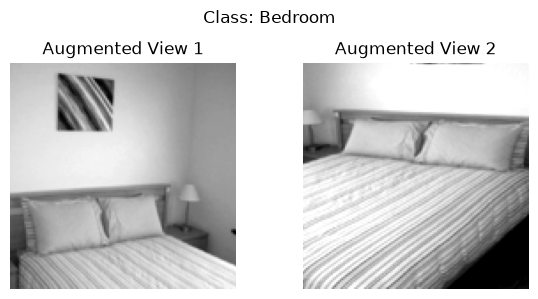

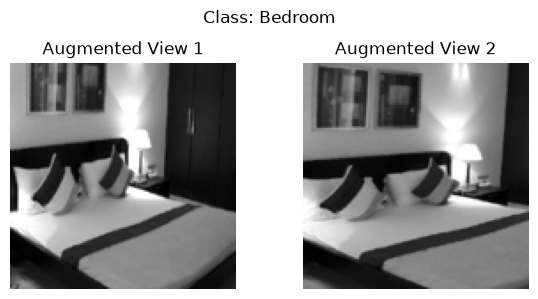

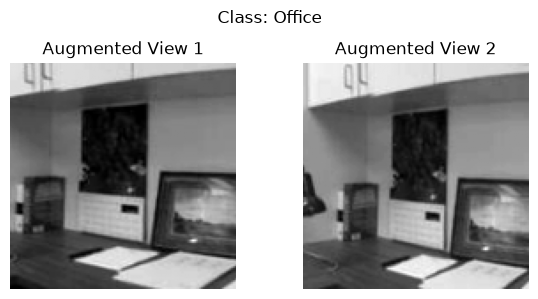

In [7]:
def imshow_pair(img_i, img_j, title=None):
    """Denormalize and display a pair of augmented views."""
    img_i = img_i.numpy().squeeze()
    img_j = img_j.numpy().squeeze()
    
    # Denormalize from [-1, 1] to [0, 1]
    img_i = (img_i * 0.5) + 0.5
    img_j = (img_j * 0.5) + 0.5
    
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(img_i, cmap='gray' if IN_CHANNELS == 1 else None)
    axes[0].set_title("Augmented View 1")
    axes[0].axis('off')
    
    axes[1].imshow(img_j, cmap='gray' if IN_CHANNELS == 1 else None)
    axes[1].set_title("Augmented View 2")
    axes[1].axis('off')
    
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Display 3 contrastive pairs from the pretraining dataset
for i in range(3):
    (view_1, view_2), label = simclr_train_dataset[i]
    imshow_pair(view_1, view_2, title=f"Class: {class_names[label]}")

## 4. Model Architecture & NT-Xent Loss

The SimCLR architecture consists of:
1. **Base Encoder $f(\cdot)$**: Extracts representation vector $h = f(x)$. Here a ResNet-18 modified for 1-channel input is used.
2. **Projection Head $g(\cdot)$**: A non-linear MLP mapping representations to latent space $z = g(h)$ where contrastive loss is computed.
3. **NT-Xent (Normalized Temperature-scaled Cross Entropy) Loss**: Measures similarity between positive pair embeddings against $2(N-1)$ negative examples in a batch.

In [8]:
class SimCLRModel(nn.Module):
    """SimCLR Architecture with ResNet-18 Backbone and 2-layer Projection Head."""
    def __init__(self, in_channels=IN_CHANNELS, feature_dim=512, projection_dim=PROJECTION_DIM):
        super(SimCLRModel, self).__init__()
        
        # Backbone Encoder
        self.encoder = models.resnet18(weights=None)
        self.encoder.conv1 = nn.Conv2d(
            in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False
        )
        self.feature_dim = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()  # Remove classifier to yield output representation h
        
        # Non-linear Projection Head g(h) = W(2) * ReLU(W(1) * h)
        self.projection_head = nn.Sequential(
            nn.Linear(self.feature_dim, self.feature_dim),
            nn.ReLU(),
            nn.Linear(self.feature_dim, projection_dim)
        )

    def forward(self, x):
        h = self.encoder(x)
        z = self.projection_head(h)
        return h, z


class NTXentLoss(nn.Module):
    """Normalized Temperature-scaled Cross Entropy Loss for Contrastive Learning."""
    def __init__(self, batch_size=BATCH_SIZE, temperature=TEMPERATURE):
        super(NTXentLoss, self).__init__()
        self.batch_size = batch_size
        self.temperature = temperature
        self.criterion = nn.CrossEntropyLoss(reduction="sum")
        
    def forward(self, z_i, z_j):
        N = z_i.shape[0]
        z = torch.cat([z_i, z_j], dim=0)  # Shape: [2N, D]
        z = F.normalize(z, dim=1)
        
        # Compute cosine similarity matrix: [2N, 2N]
        sim_matrix = torch.matmul(z, z.T) / self.temperature
        
        # Mask self-contrastive similarity scores
        mask = torch.eye(2 * N, dtype=torch.bool, device=z.device)
        sim_matrix = sim_matrix.masked_fill(mask, -9e15)
        
        # Positive target indices for NT-Xent: (i, i+N) and (i+N, i)
        targets = torch.cat([
            torch.arange(N, 2 * N, device=z.device),
            torch.arange(0, N, device=z.device)
        ], dim=0)
        
        loss = self.criterion(sim_matrix, targets)
        return loss / (2 * N)

# Instantiate SimCLR model and Loss
simclr_model = SimCLRModel().to(device)
nt_xent_loss = NTXentLoss(batch_size=BATCH_SIZE, temperature=TEMPERATURE)
print(simclr_model)

SimCLRModel(
  (encoder): ResNet(
    (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05,

## 5. Pretraining & Evaluation Utilities

1. **Pretraining Loop**: Optimizes the encoder and projection head on contrastive NT-Xent loss.
2. **Linear Classifier Protocol**: Freezes the pretrained encoder, attaches a linear layer, and trains it using supervised CrossEntropyLoss to evaluate representation quality.

In [9]:
def train_simclr_epoch(model, dataloader, criterion, optimizer, device):
    """Pretrains the encoder and projection head for one contrastive epoch."""
    model.train()
    running_loss = 0.0
    
    for (x_i, x_j), _ in dataloader:
        x_i, x_j = x_i.to(device), x_j.to(device)
        
        optimizer.zero_grad()
        _, z_i = model(x_i)
        _, z_j = model(x_j)
        
        loss = criterion(z_i, z_j)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * x_i.size(0)
        
    epoch_loss = running_loss / len(dataloader.dataset)
    return epoch_loss


class LinearEvaluationModel(nn.Module):
    """Linear classifier built on top of a frozen base encoder."""
    def __init__(self, encoder, feature_dim, num_classes):
        super(LinearEvaluationModel, self).__init__()
        self.encoder = encoder
        for param in self.encoder.parameters():
            param.requires_grad = False  # Freeze encoder parameters
        self.fc = nn.Linear(feature_dim, num_classes)

    def forward(self, x):
        with torch.no_grad():
            h = self.encoder(x)
        out = self.fc(h)
        return out


def train_eval_classifier(model, dataloader, criterion, optimizer, device):
    """Trains downstream linear evaluation layer."""
    model.train()
    running_loss, running_corrects = 0.0, 0
    
    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        _, preds = torch.max(outputs, 1)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
        
    return running_loss / len(dataloader.dataset), (running_corrects.double() / len(dataloader.dataset)).item()


def evaluate_classifier(model, dataloader, criterion, device):
    """Evaluates linear classifier on validation/test set."""
    model.eval()
    running_loss, running_corrects = 0.0, 0
    
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)
            
    return running_loss / len(dataloader.dataset), (running_corrects.double() / len(dataloader.dataset)).item()

## 6. Pretraining and Experiment Tracking

Executes contrastive pretraining followed by linear probe evaluation.

In [10]:
PRETRAIN_EPOCHS = 15
LINEAR_EPOCHS = 10
LR_PRETRAIN = 1e-3
LR_LINEAR = 1e-2

optimizer_pretrain = optim.Adam(simclr_model.parameters(), lr=LR_PRETRAIN, weight_decay=1e-6)

print("--- Starting SimCLR Unsupervised Pretraining ---")
pretrain_losses = []
start_time = time.time()

for epoch in range(1, PRETRAIN_EPOCHS + 1):
    loss = train_simclr_epoch(simclr_model, simclr_train_loader, nt_xent_loss, optimizer_pretrain, device)
    pretrain_losses.append(loss)
    print(f"Epoch {epoch:02d}/{PRETRAIN_EPOCHS:02d} | Contrastive Loss: {loss:.4f}")

print(f"Pretraining completed in {(time.time() - start_time)/60:.2f} minutes.")

# Plot pretraining loss
plt.figure(figsize=(6, 4))
plt.plot(range(1, PRETRAIN_EPOCHS + 1), pretrain_losses, marker='o', label='NT-Xent Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('SimCLR Contrastive Pretraining Loss')
plt.grid(True)
plt.legend()
plt.show()

--- Starting SimCLR Unsupervised Pretraining ---


Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/lib64/python3.14/multiprocessing/forkserver.py", line 353, in main
    code = _serve_one(child_r, fds,
                      unused_fds,
                      old_handlers)
  File "/usr/lib64/python3.14/multiprocessing/forkserver.py", line 393, in _serve_one
    code = spawn._main(child_r, parent_sentinel)
  File "/usr/lib64/python3.14/multiprocessing/spawn.py", line 132, in _main
    self = reduction.pickle.load(from_parent)
AttributeError: module '__main__' has no attribute 'SimCLRTransform'
  File "/usr/lib64/python3.14/multiprocessing/forkserver.py", line 353, in main
    code = _serve_one(child_r, fds,
                      unused_fds,
                      old_handlers)
  File "/usr/lib64/python3.14/multiprocessing/forkserver.py", line 393, in _serve_one
    code = spawn._main(child_r, parent_sentinel)
  File "/usr/lib64/python3.14/multiprocessing/spawn.py", line 132, in _main
    self = reduction.

RuntimeError: DataLoader worker (pid(s) 1110924, 1110925) exited unexpectedly

In [ ]:
print("--- Starting Linear Probe Evaluation Protocol ---")

eval_model = LinearEvaluationModel(simclr_model.encoder, simclr_model.feature_dim, num_classes).to(device)
criterion_eval = nn.CrossEntropyLoss()
optimizer_eval = optim.SGD(eval_model.fc.parameters(), lr=LR_LINEAR, momentum=0.9)

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(1, LINEAR_EPOCHS + 1):
    tr_loss, tr_acc = train_eval_classifier(eval_model, linear_train_loader, criterion_eval, optimizer_eval, device)
    val_loss, val_acc = evaluate_classifier(eval_model, val_loader, criterion_eval, device)
    
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(val_acc)
    
    print(f"Epoch {epoch:02d}/{LINEAR_EPOCHS:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history['train_loss'], label='Train Loss')
ax1.plot(history['val_loss'], label='Val Loss')
ax1.set_title('Linear Probe Loss')
ax1.set_xlabel('Epoch')
ax1.legend()
ax1.grid(True)

ax2.plot(history['train_acc'], label='Train Acc')
ax2.plot(history['val_acc'], label='Val Acc')
ax2.set_title('Linear Probe Accuracy')
ax2.set_xlabel('Epoch')
ax2.legend()
ax2.grid(True)
plt.show()

## 7. Final Evaluation

Evaluates representation quality on the unseen test dataset.

In [ ]:
test_loss, test_acc = evaluate_classifier(eval_model, test_loader, criterion_eval, device)

print("Final Evaluation Summary")
summary_df = pd.DataFrame([{
    "Test Loss": f"{test_loss:.4f}",
    "Test Accuracy": f"{test_acc * 100:.2f}%"
}])
display(summary_df)